# Deep learning · Part B: picking one hour of the Geysers

**Run a published picker on one hour of continuous Geysers data from 131 stations. Do its picks
agree with the analysts', what does the catalogue miss, and does the sampling rate matter?**

[Part A](https://colab.research.google.com/github/AI4EPS/EPS207_Observational_Seismology/blob/main/docs/notebooks/05a_deep_learning.ipynb)
built a U-Net picker and trained it on labelled event windows. Here we take the network the field
actually uses, PhaseNet (Zhu & Beroza 2019), with its published weights, and run it the way it is
run in practice: on continuous records, hour after hour, on every station, with nobody telling it
where the earthquakes are. There are no labels for most of what it finds, so we judge it two ways:
against the picks the Northern California Seismic Network's analysts made for the same hour, and
against itself, by asking whether the picks on 131 stations line up into earthquakes.

You can run it without running Part A first. A GPU makes it faster (Colab: *Runtime → Change
runtime type → GPU*), but every step also runs on a CPU.

## The questions this notebook answers

1. Which data do we have for one hour, and how are they read from two public archives? (B.1)
2. How does PhaseNet turn a continuous three-component record into picks? (B.2)
3. What does one hour of picks on 131 stations look like? (B.3)
4. Do PhaseNet's picks agree with the analysts' picks? (B.4)
5. How many earthquakes does the catalogue miss in this hour? (B.5)
6. PhaseNet was trained on 100 Hz data. What should we do with data recorded at 200 or 500 Hz? (B.6)
7. Where does the picker go wrong? (B.7)


In [1]:
import importlib.util
import io
import pathlib
import subprocess
import sys
import time
import urllib.request

# obspy, the toolkit of the field, is not installed on Colab; install whatever is missing.
REQUIRED = ["numpy", "pandas", "matplotlib", "scipy", "requests", "torch", "obspy"]
missing = [pkg for pkg in REQUIRED if importlib.util.find_spec(pkg) is None]
if missing:
    print("installing", ", ".join(missing), "...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

# The course's data module sits beside the notebook on DataHub; Colab opens the notebook alone, so
# there it is fetched.
BASE = "https://raw.githubusercontent.com/AI4EPS/EPS207_Observational_Seismology/main/docs/notebooks"
for module in ("geysers_data.py",):
    if "google.colab" in sys.modules or importlib.util.find_spec(module[:-3]) is None:
        for attempt in range(4):
            try:
                urllib.request.urlretrieve(f"{BASE}/{module}", module)
                break
            except Exception as exc:
                if attempt == 3:
                    raise RuntimeError(f"could not fetch {module}: {exc}; re-run this cell") from None
                time.sleep(2 * (attempt + 1))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import scipy.signal
import torch
import torch.nn as nn
import torch.nn.functional as F
import obspy
from obspy.io.mseed.util import get_record_information
from concurrent.futures import ThreadPoolExecutor
import geysers_data as gd

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
CACHE = pathlib.Path("data/picking_hour"); CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
print("running on", DEVICE)


running on mps


## B.1 · One hour, two kinds of network

**The hour.** We work on one hour: from 23:30 on 19 October 2022 to 00:30 on 20 October (UTC; it
was 16:30–17:30 in California). The first half is ordinary. Just before midnight an M 3.3 starts a
burst — another M 3.3 within a minute, an M 3.2 three and a half minutes later, and dozens of smaller
earthquakes after them (the list is printed below). A
quiet half and a busy half in one hour let us see what the picker does on noise and what it does
when earthquakes overlap.

**The permanent network.** The final project's station table (`gd.sites()`) lists every station
inside the 40 km study circle. Most belong to the BG network, the borehole geophones Calpine runs
over the field, recorded at 500 samples per second (500 Hz); the others are the USGS (NC) and
Berkeley (BK) short-period, broadband and strong-motion stations, recorded at 100 Hz. A station in
the table is not always a station with data: we keep those that were open on that day and have
files in the NCEDC public archive. Their continuous records are stored as one file per channel per
day, on Amazon S3.

**The dense array.** From 2018 to 2024 the California Energy Commission (CEC) ran a temporary array
of 91 three-component geophones, about 500 m apart, over a 5 × 5 km patch of the field, recorded at
200 Hz. Its records are stored as one file per channel per **hour**, on Google Cloud Storage
(`gs://quakeflow_waveform/Geysers_CEC`, public). The files name the nodes `S00`–`S95`; the coordinate
table names them `ST001`–`ST100`. The two match number for number (`S12` is `ST012`), except that
`S00` is `ST100`.


In [2]:
T0, T1 = obspy.UTCDateTime("2022-10-19T23:30:00"), obspy.UTCDateTime("2022-10-20T00:30:00")
DAYS = (292, 293)                                    # day of the year of 19 and 20 October 2022

site = gd.sites()                                    # the project's station table
opened = pd.to_datetime(site["first"]) < pd.Timestamp("2022-10-19")
still = pd.to_datetime(site["last"]) > pd.Timestamp("2022-10-21")
site = site[opened & still & (site.d_km <= gd.RADIUS_KM)]
print(f"{len(site)} project stations open on the day, inside {gd.RADIUS_KM:.0f} km")


67 project stations open on the day, inside 40 km


Which of them have files that day? The archive answers by listing a folder. We keep one instrument
per station, preferring a velocity sensor (broadband `HH`, borehole `DP`, short-period `EH`) to an
accelerometer (`HN`, `CN`), because PhaseNet was trained on velocity records.


In [3]:
def s3_day(net, day):
    """Every channel file of one network for one day in the NCEDC archive: (station, channel, key)."""
    rows = []
    for key, size in gd.s3_list(f"continuous_waveforms/{net}/2022/2022.{day}/"):
        sta, _, cha, loc = key.split("/")[-1].split(".")[:4]
        rows.append(dict(Network=net, Station=sta, cha=cha, loc=loc, day=day, key=key))
    return rows

PREFER = ["HH", "DP", "EH", "HN", "CN"]
files = pd.DataFrame([r for net in site.Network.unique() for d in DAYS for r in s3_day(net, d)])
files = files.merge(site[["Network", "Station"]], on=["Network", "Station"])
files = files[files.cha.str[:2].isin(PREFER)]
best = (files.assign(rank=files.cha.str[:2].map(PREFER.index))
        .groupby(["Network", "Station"])["rank"].min().rename("best").reset_index())
files = files.merge(best, on=["Network", "Station"])
files = files[files.cha.str[:2].map(PREFER.index) == files.best]
both_days = files.groupby(["Network", "Station"]).day.nunique() == 2
files = files.set_index(["Network", "Station"]).loc[both_days[both_days].index].reset_index()
net_stations = site.merge(files[["Network", "Station"]].drop_duplicates(), on=["Network", "Station"])
print(f"{len(net_stations)} of them have files on both days:",
      files.drop_duplicates(["Network", "Station"]).cha.str[:2].value_counts().to_dict())
print("open but no files:", sorted(set(site.Station) - set(net_stations.Station)))


57 of them have files on both days: {'DP': 32, 'EH': 13, 'CN': 5, 'HH': 4, 'HN': 3}
open but no files: ['1216', '68035', '68328', '68676', 'ADS2', 'ADSP', 'COB', 'GALB', 'HOPS', 'N005']


In [4]:
def gcs_list(prefix):
    """Object names under a prefix of the public CEC bucket (Google's JSON listing needs no login)."""
    url, names, token = "https://storage.googleapis.com/storage/v1/b/quakeflow_waveform/o", [], None
    while True:
        for attempt in range(5):
            try:
                r = requests.get(url, params={"prefix": prefix, **({"pageToken": token} if token else {})}, timeout=60).json()
                break
            except Exception:
                if attempt == 4:
                    raise RuntimeError("Google Cloud Storage did not answer; re-run this cell") from None
                time.sleep(2 ** attempt)
        names += [o["name"] for o in r.get("items", [])]
        token = r.get("nextPageToken")
        if not token:
            return names

cec_files = (gcs_list("Geysers_CEC/2022/2022.292/2022.292.23.")
             + gcs_list("Geysers_CEC/2022/2022.293/2022.293.00."))
nodes = gd.cec()
code = lambda name: "S00" if name == "ST100" else "S" + name[3:]
nodes["sta"] = nodes.Name.map(code)
nodes = nodes[nodes.sta.isin({n.split(".")[-2] for n in cec_files})].reset_index(drop=True)
print(f"{len(nodes)} of the {len(gd.cec())} CEC nodes recorded in the hour ({len(cec_files)} hourly files)")


74 of the 91 CEC nodes recorded in the hour (453 hourly files)


**The catalogue and the analysts' picks.** NCEDC serves its catalogue through an FDSN *event*
service, and asked for `includearrivals`, it returns every pick that located each earthquake. A
pick carries an `evaluation_mode`: *manual* means an analyst made or reviewed it, *automatic* means
the network's real-time picker made it and nobody changed it.


In [5]:
def fdsn_events():
    url = "https://service.ncedc.org/fdsnws/event/1/query"
    q = dict(starttime=str(T0)[:19], endtime=str(T1)[:19], minlatitude=gd.REGION[2], maxlatitude=gd.REGION[3],
             minlongitude=gd.REGION[0], maxlongitude=gd.REGION[1], includearrivals="true")
    for attempt in range(4):
        try:
            r = requests.get(url, params=q, timeout=120); r.raise_for_status()
            return obspy.read_events(io.BytesIO(r.content))
        except Exception:
            time.sleep(5 * (attempt + 1))
    raise RuntimeError("NCEDC event service did not answer; re-run this cell")

cat = fdsn_events()
ev, picks = [], []
for e in cat:
    o = e.preferred_origin() or e.origins[0]
    m = e.preferred_magnitude() or (e.magnitudes[0] if e.magnitudes else None)
    eid = str(e.resource_id).split("/")[-1]
    ev.append(dict(event_id=eid, time=o.time, t=o.time - T0, lat=o.latitude, lon=o.longitude,
                   depth=o.depth / 1000, mag=m.mag if m else np.nan))
    picks += [dict(event_id=eid, net=p.waveform_id.network_code, sta=p.waveform_id.station_code,
                   phase=p.phase_hint, mode=p.evaluation_mode, t=p.time - T0) for p in e.picks]
ev = pd.DataFrame(ev).sort_values("t").reset_index(drop=True)
ncedc = pd.DataFrame(picks)
print(f"{len(ev)} catalogue events in the hour, M {ev.mag.min():.1f}–{ev.mag.max():.1f}; "
      f"{len(ncedc)} picks: {ncedc.groupby(['phase', 'mode']).size().to_dict()}")
n_p, n_s = (ncedc.phase == "P").sum(), (ncedc.phase == "S").sum()
print(f"{n_p:,} P picks and {n_s} S picks: one S for every {n_p / n_s:.0f} P")
print("the earthquakes of M ≥ 3:", ", ".join(f"M {r.mag:.1f} at {str(r.time)[11:19]}" for r in ev[ev.mag >= 3].itertuples()))


67 catalogue events in the hour, M -0.1–3.3; 1747 picks: {('P', 'automatic'): 632, ('P', 'manual'): 1054, ('S', 'manual'): 61}
1,686 P picks and 61 S picks: one S for every 28 P
the earthquakes of M ≥ 3: M 3.3 at 23:59:04, M 3.3 at 23:59:50, M 3.2 at 00:02:34


The catalogue made 1,686 P picks for this hour and 61 S picks — one S for every 28 P. Its
real-time picker makes only P picks; the S picks are the analysts'. An S pick is harder to make by
hand, and on many of the network's stations only the vertical component is recorded, on which S is
weak.

**One order for every station.** Every figure below lists stations in one order: by their distance
along the line A–A′ of Session 4, *Clustering*, which runs north-west to south-east along the long
axis of the field's seismicity. Rows close together are stations at about the same position along
that axis (a station off to the side of the line is placed at the point of the line nearest to it).
The 74 dense-array nodes, which sit in the middle of the line, fill most of the middle rows, mixed
with the BG boreholes around them; the figures shade their rows.


In [6]:
A_KM, AZ = np.array([-6.773, 4.188]), np.radians(124.3)     # start of A–A′ (km east, north of gd.CENTER); azimuth
U = np.array([np.sin(AZ), np.cos(AZ)])

def along(lat, lon):
    """Distance along A–A′ (km)."""
    xy = np.c_[(np.asarray(lon) - gd.CENTER[1]) * gd.KM_LON, (np.asarray(lat) - gd.CENTER[0]) * gd.KM_LAT]
    return (xy - A_KM) @ U

stations = pd.concat([
    pd.DataFrame(dict(net=net_stations.Network, sta=net_stations.Station, lat=net_stations.lat,
                      lon=net_stations.lon, kind=net_stations.klass)),
    pd.DataFrame(dict(net="CEC", sta=nodes.sta, lat=nodes.lat, lon=nodes.lon, kind="CEC node"))])
stations["s"] = along(stations.lat, stations.lon)
stations = stations.sort_values("s").reset_index(drop=True)
stations["row"] = np.arange(len(stations))
print(f"{len(stations)} stations in all: {stations.kind.value_counts().to_dict()}")


131 stations in all: {'CEC node': 74, 'BG': 37, 'short-period': 11, 'broadband': 7, 'strong-motion': 2}


The map shows the two networks at two scales. On the left, the permanent stations spread over the
40 km circle; on the right, the dense array sits directly over the earthquakes of the hour.


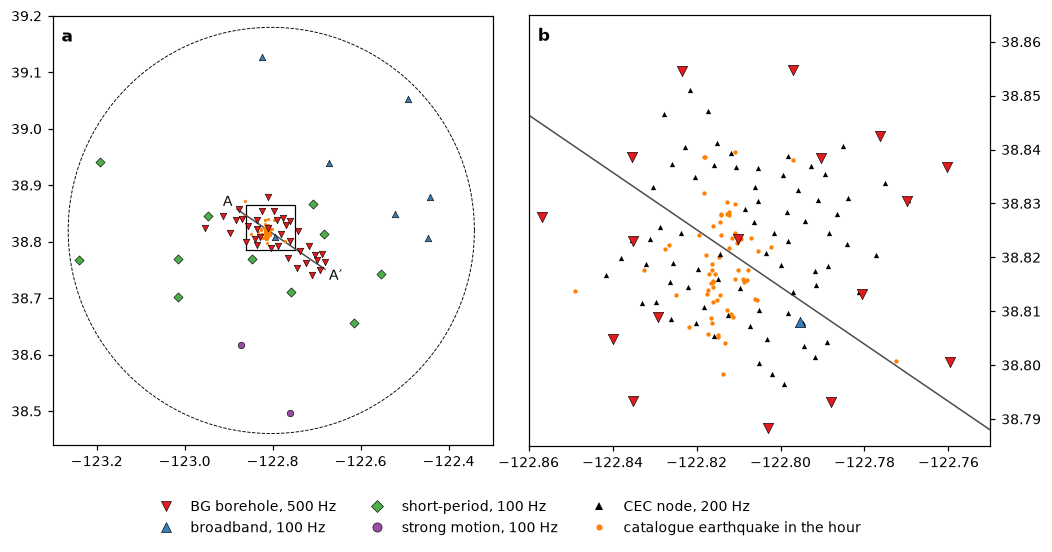

In [7]:
from matplotlib.lines import Line2D
ARR = [-122.86, -122.75, 38.785, 38.865]
STYLE = {"BG": ("v", "#e41a1c", "BG borehole, 500 Hz"), "broadband": ("^", "#377eb8", "broadband, 100 Hz"),
         "short-period": ("D", "#4daf4a", "short-period, 100 Hz"), "strong-motion": ("o", "#984ea3", "strong motion, 100 Hz")}
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw=dict(width_ratios=[1, 1.05], wspace=0.08))
for ax, reg, size in ((axs[0], gd.REGION, 18), (axs[1], ARR, 46)):
    ax.scatter(ev.lon, ev.lat, s=8 if size > 20 else 4, c="#ff7f00", lw=0, zorder=3)
    if ax is axs[1]:
        ax.scatter(nodes.lon, nodes.lat, s=12, marker="^", c="k", lw=0, zorder=4)
    for k, (m, c, _) in STYLE.items():
        q = stations[stations.kind == k]
        ax.scatter(q.lon, q.lat, s=size, marker=m, facecolor=c, edgecolor="k", lw=.4, zorder=5)
    ax.set(xlim=reg[:2], ylim=reg[2:], aspect=1 / np.cos(np.radians(gd.CENTER[0])))
    ax.grid(False)
th = np.linspace(0, 2 * np.pi, 361)
axs[0].plot(gd.CENTER[1] + gd.RADIUS_KM / gd.KM_LON * np.cos(th), gd.CENTER[0] + gd.RADIUS_KM / gd.KM_LAT * np.sin(th), "k--", lw=.6)
axs[0].plot([ARR[0], ARR[1], ARR[1], ARR[0], ARR[0]], [ARR[2], ARR[2], ARR[3], ARR[3], ARR[2]], "k", lw=.8)
end = lambda d: (gd.CENTER[1] + (A_KM[0] + d * U[0]) / gd.KM_LON, gd.CENTER[0] + (A_KM[1] + d * U[1]) / gd.KM_LAT)
(x0, y0), (x1, y1) = end(0), end(21)
for ax in axs:
    ax.plot([x0, x1], [y0, y1], color="0.3", lw=1, zorder=2)
axs[0].text(x0, y0, "A ", ha="right", va="bottom", fontsize=9); axs[0].text(x1, y1, " A′", ha="left", va="top", fontsize=9)
axs[1].yaxis.tick_right()
for k, ax in enumerate(axs):
    ax.text(.02, .97, "ab"[k], transform=ax.transAxes, fontsize=11, fontweight="bold", va="top")
h = [Line2D([], [], ls="none", marker=m, mfc=c, mec="k", mew=.4, ms=6, label=l) for m, c, l in STYLE.values()]
h += [Line2D([], [], ls="none", marker="^", mfc="k", mec="none", ms=5, label="CEC node, 200 Hz"),
      Line2D([], [], ls="none", marker="o", mfc="#ff7f00", mec="none", ms=4, label="catalogue earthquake in the hour")]
fig.legend(handles=h, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.show()


## B.2 · PhaseNet on a continuous record

**What PhaseNet is.** PhaseNet (Zhu & Beroza 2019) is the U-Net of Part A, trained on "more than seven
million waveform samples extracted from over thirty years of earthquake recordings" with the P and
S arrival times that NCEDC analysts picked. Every training record was sampled at 100 Hz and cut into 30 s windows of 3,001
samples, and each arrival was labelled with a Gaussian of standard deviation 0.1 s, as in Part A.
Its weights are published, so we can run exactly the network the paper trained.

**Reading the records.** First, two readers, one for each archive. A CEC node's hour is two hourly
files per component (23:00 on the 19th and 00:00 on the 20th), fetched whole. A network station's
hour sits inside two *day* files of about 50 MB each, of which we need half an hour from each. A
miniSEED file is a sequence of fixed 4,096-byte records, and each record's header states the time of
its first sample, so we can find the records that cover our hour by bisection — read the header of
the middle record, keep the half that contains the hour, repeat — and then download only those,
with an HTTP *Range* request. A few dozen small requests replace downloading the whole day.


In [8]:
def get(url, rng=None):
    """GET with retries; rng=(first, last) asks for those bytes only."""
    for attempt in range(5):
        try:
            r = requests.get(url, headers={"Range": f"bytes={rng[0]}-{rng[1]}"} if rng else None, timeout=60)
            if r.status_code in (200, 206):
                return r
        except requests.RequestException:
            pass
        time.sleep(2 ** attempt)
    raise IOError(f"could not read {url}; re-run the cell")


REC = 4096
print(f"miniSEED record length in the NCEDC archive: {REC:,} bytes")


def window(key, t0, t1):
    """The records of one NCEDC channel-day file that overlap [t0, t1], by bisection on record times."""
    url = f"{gd.BUCKET}/{key}"
    n = int(get(url, (0, 0)).headers["Content-Range"].split("/")[-1]) // REC
    start = lambda k: get_record_information(io.BytesIO(get(url, (k * REC, k * REC + 511)).content))["starttime"]
    def last_before(t):                              # the last record that starts at or before t
        lo, hi = 0, n - 1
        while hi - lo > 1:
            mid = (lo + hi) // 2
            lo, hi = (mid, hi) if start(mid) <= t else (lo, mid)
        return lo
    a, b = last_before(t0), min(last_before(t1) + 1, n - 1)
    return obspy.read(io.BytesIO(get(url, (a * REC, (b + 1) * REC - 1)).content))


def read_station(net, sta):
    """One hour of one station, [T0, T1], cached on disk after the first read."""
    path = CACHE / f"{net}.{sta}.mseed"
    if path.exists():
        return obspy.read(str(path))
    st = obspy.Stream()
    if net == "CEC":
        for name in cec_files:
            if name.split(".")[-2] == sta:
                st += obspy.read(io.BytesIO(get("https://storage.googleapis.com/quakeflow_waveform/" + name).content))
    else:
        for key in files[(files.Network == net) & (files.Station == sta)].key:
            st += window(key, T0, T1)
    st.trim(T0 - 5, T1 + 5)
    if len(st):                                      # a station can have files but no data in the hour
        st.write(str(path), format="MSEED")
    return st


miniSEED record length in the NCEDC archive: 4,096 bytes


**From a record to the network's input.** Each step below copies what PhaseNet's own code does
with a continuous record before the network sees it.

1. *Merge.* A day of data can arrive in several pieces; each piece has its mean removed and gaps are
   filled with zeros.
2. *High-pass at 1 Hz*, with a causal filter (it uses only past samples), so that nothing is
   smeared to before an onset.
3. *Choose the sampling rate.* PhaseNet never sees a time axis, only samples, so the rate we give it
   changes what it sees. We keep the recorded rate of the dense array (200 Hz) and of the 100 Hz
   stations, and lower the BG boreholes from 500 to 250 Hz; B.6 shows why.
4. *Standardise.* Each component has a running mean subtracted and is divided by a running standard
   deviation, both measured in windows of 3,000 samples centred every 1,500 samples and interpolated
   in between. The training windows were standardised as a whole; a long record cannot be, because
   one large earthquake would make every small one in the hour vanish.


In [9]:
def prepare(st, fs, t0=T0, t1=T1):
    """Stream -> (3, n) array, components in the order E, N, Z, at fs samples per second."""
    st = st.copy()
    st.merge(method=1)
    sos = scipy.signal.butter(4, 1.0, btype="highpass", fs=fs, output="sos")
    for tr in st:
        x = np.ma.masked_array(tr.data, np.ma.getmaskarray(tr.data)).astype(float)
        tr.data = np.ma.filled(x - x.mean(), 0.0)
        if tr.stats.sampling_rate > fs:                               # lower the rate (BG: 500 -> 250 Hz)
            tr.filter("lowpass", freq=0.4 * fs, corners=4, zerophase=False)
            q = tr.stats.sampling_rate / fs
            if abs(q - round(q)) < 1e-6:
                tr.decimate(int(round(q)), no_filter=True)
            else:
                tr.data = scipy.signal.resample_poly(tr.data, int(fs), int(tr.stats.sampling_rate)); tr.stats.sampling_rate = fs
        elif tr.stats.sampling_rate < fs:                             # raise the rate (only in B.6)
            tr.data = scipy.signal.resample_poly(tr.data, int(fs), int(tr.stats.sampling_rate)); tr.stats.sampling_rate = fs
        tr.data = scipy.signal.sosfilt(sos, tr.data)
        if tr.stats.channel[1] == "N":                                # an accelerometer: pick on velocity
            tr.integrate(); tr.data = scipy.signal.sosfilt(sos, tr.data)
    st.trim(t0, t1, pad=True, fill_value=0.0)
    n = int(round((t1 - t0) * fs))
    x = np.zeros((3, n), np.float32)
    order = {"E": 0, "N": 1, "Z": 2, "3": 0, "2": 1, "1": 2}     # BG's DP1 is vertical, DP2 north, DP3 east
    for tr in st:
        x[order[tr.stats.channel[-1]], :min(n, tr.stats.npts)] = tr.data[:n]
    return x


def standardise(x, window=3000):
    """Running mean and standard deviation per component (PhaseNet's normalize_long)."""
    nt, shift = x.shape[-1], window // 2
    xp = np.pad(x.astype(np.float64), ((0, 0), (shift, shift)), mode="reflect")
    c1, c2 = (np.pad(np.cumsum(a, -1), ((0, 0), (1, 0))) for a in (xp, xp * xp))
    s = np.arange(0, xp.shape[-1] - window + 1, shift)                # a window every `shift` samples
    mean = (c1[:, s + window] - c1[:, s]) / window
    std = np.sqrt(np.clip((c2[:, s + window] - c2[:, s]) / window - mean ** 2, 0, None))
    k = (nt + shift - 1) // shift
    knot = np.arange(k + 1) * shift; knot[-1] = nt; use = np.clip(np.arange(k + 1), 1, k - 1)
    m = np.stack([np.interp(np.arange(nt), knot, a[use]) for a in mean])
    sd = np.stack([np.interp(np.arange(nt), knot, a[use]) for a in std])
    live = int((sd.sum(-1) > 0).sum())                                # a dead component counts as missing:
    gain = 3.0 / live if 0 < live < 3 else 1.0                        # the live ones are scaled up to make up
    return ((x - m) / np.where(sd == 0, 1, sd) * gain).astype(np.float32)

print("PhaseNet's training windows: 3,001 samples (30 s at 100 Hz); "
      "standardisation of a long record: windows of 3,000 samples, one every 1,500")


PhaseNet's training windows: 3,001 samples (30 s at 100 Hz); standardisation of a long record: windows of 3,000 samples, one every 1,500


**The network.** It is Part A's `UNet2018` with one difference that matters only for the published
weights. The weights were trained in TensorFlow, whose "same" padding for a convolution of stride 4
and kernel 7 adds one sample on the left and two on the right, where Part A's version adds three on
each side. With the wrong padding, every stage of the encoder is shifted by part of a sample; the
shifts add up through the network, and the published weights then give wrong probabilities. The
three padding rules below make the class reproduce PhaseNet.

The network contains only convolutions, so it accepts a record of any length. We give it the whole
hour in one pass rather than cutting it into 30 s windows: no window edges, and no seams to stitch.


In [10]:
class PhaseNet2018(nn.Module):
    """PhaseNet's U-Net (Part A's UNet2018 with TensorFlow's 'same' padding); logits (batch, 3, samples)."""

    def __init__(self, depths=5, filters_root=8, kernel_size=7, pool_size=4):
        super().__init__()
        K, S = kernel_size, pool_size
        self.K, self.S, self.depths = K, S, depths
        self.input_conv = nn.Conv1d(3, filters_root, K, padding=K // 2)
        self.input_bn = nn.BatchNorm1d(filters_root, eps=1e-3)
        self.down_conv1, self.down_bn1 = nn.ModuleList(), nn.ModuleList()
        self.down_conv3, self.down_bn3 = nn.ModuleList(), nn.ModuleList()
        c = filters_root
        for d in range(depths):
            f = 2 ** d * filters_root                                      # 8, 16, 32, 64, 128 channels
            self.down_conv1.append(nn.Conv1d(c, f, K, padding=K // 2, bias=False)); self.down_bn1.append(nn.BatchNorm1d(f, eps=1e-3))
            if d < depths - 1:
                self.down_conv3.append(nn.Conv1d(f, f, K, stride=S, bias=False)); self.down_bn3.append(nn.BatchNorm1d(f, eps=1e-3))
            c = f
        self.up_conv0, self.up_bn0 = nn.ModuleList(), nn.ModuleList()
        self.up_conv1, self.up_bn1 = nn.ModuleList(), nn.ModuleList()
        for d in range(depths - 2, -1, -1):
            f = 2 ** d * filters_root
            self.up_conv0.append(nn.ConvTranspose1d(c, f, K, stride=S, bias=False)); self.up_bn0.append(nn.BatchNorm1d(f, eps=1e-3))
            self.up_conv1.append(nn.Conv1d(2 * f, f, K, padding=K // 2, bias=False)); self.up_bn1.append(nn.BatchNorm1d(f, eps=1e-3))
            c = f
        self.output_conv = nn.Conv1d(filters_root, 3, 1)

    def forward(self, x):
        K, S = self.K, self.S
        net = F.relu(self.input_bn(self.input_conv(x)))
        skips = []
        for d in range(self.depths):
            net = F.relu(self.down_bn1[d](self.down_conv1[d](net)))
            skips.append(net)
            if d < self.depths - 1:
                r = net.shape[-1] % S                                      # rule 1: TensorFlow pads K - S
                pad = K - S if r == 0 else max(K - r, 0)                    # samples (or K - r), the extra
                net = F.pad(net, (pad // 2, pad - pad // 2))                # one on the right
                net = F.relu(self.down_bn3[d](self.down_conv3[d](net)))
        for i, d in enumerate(range(self.depths - 2, -1, -1)):
            n = net.shape[-1]
            net = self.up_conv0[i](net)[..., (K - S) // 2:(K - S) // 2 + n * S]   # rule 2: keep n * S samples
            net = F.relu(self.up_bn0[i](net))
            skip = skips[d]; c0 = (net.shape[-1] - skip.shape[-1]) // 2
            net = torch.cat([skip, net[..., c0:c0 + skip.shape[-1]]], 1)        # rule 3: centre on the skip
            net = F.relu(self.up_bn1[i](self.up_conv1[i](net)))
        return self.output_conv(net)


def load_phasenet():
    path = CACHE.parent / "phasenet2018.pth"
    if not path.exists():
        path.write_bytes(get("https://github.com/AI4EPS/models/releases/download/PhaseNet-2018/phasenet2018.pth").content)
    state = torch.load(path, map_location="cpu", weights_only=False)["model"]
    state = {k.removeprefix("backbone."): (v.squeeze(2) if v.ndim == 4 else v)     # the 2-D kernels (1 x 7)
             for k, v in state.items() if k.startswith("backbone.")}            # become 1-D kernels (7)
    net = PhaseNet2018(); net.load_state_dict(state)
    return net.eval().to(DEVICE)


phasenet = load_phasenet()
print(f"PhaseNet: {sum(p.numel() for p in phasenet.parameters()):,} parameters, on {DEVICE}")


PhaseNet: 268,443 parameters, on mps


**From probabilities to picks.** The network returns, for every sample, the probability that it is
noise, a P arrival or an S arrival. A **pick** is a local maximum of the P (or S) probability that is
at least 0.3 and is the largest value within half a second on either side — the rule of Part A
(PhaseNet's code writes it as 50 samples, which is half a second at 100 Hz). The threshold trades
missed arrivals against false ones, as Part A showed; 0.3 is PhaseNet's default. Where we need
fewer false picks (the figures, the detections of B.5), we keep only picks of 0.5 or more.


In [11]:
@torch.no_grad()
def predict(x):
    """Probabilities (3, n) for a prepared record: the whole record in one pass."""
    z = standardise(x); pad = -z.shape[-1] % 16
    z = torch.from_numpy(np.pad(z, ((0, 0), (0, pad))))[None].to(DEVICE)
    return torch.softmax(phasenet(z), 1)[0, :, :x.shape[-1]].cpu().numpy()


VMIN, HALF = 0.3, 0.5
print(f"a pick: a local maximum of at least {VMIN}, the largest within {HALF} s either side")


def detect(prob, fs, vmin=VMIN, half=HALF):
    """Picks: (phase, sample index, probability) at local maxima above vmin."""
    kernel = 2 * int(round(half * fs)) + 1                    # 101 samples at 100 Hz
    out = []
    for k, ph in ((1, "P"), (2, "S")):
        p = torch.from_numpy(prob[k])[None, None]
        peak = F.max_pool1d(p, kernel, 1, kernel // 2)[0, 0].numpy() == prob[k]
        for i in np.where(peak & (prob[k] >= vmin))[0]:
            out.append((ph, i, float(prob[k][i])))
    return out


a pick: a local maximum of at least 0.3, the largest within 0.5 s either side


**One node, one earthquake.** We run the hour of node `S56` through these steps and look at the
M 1.3 of 00:18:38, whose epicentre is 0.5 km from the node — a typical size for the hour. The three components go in;
two probability curves come out; their peaks are the picks.


rates given to PhaseNet: {'CEC': 200.0, 'BG': 250.0}, every other station 100 Hz; S56 is 0.5 km from the epicentre


P pick 0.39 s after the origin time, probability 0.98
S pick 0.80 s after the origin time, probability 0.72


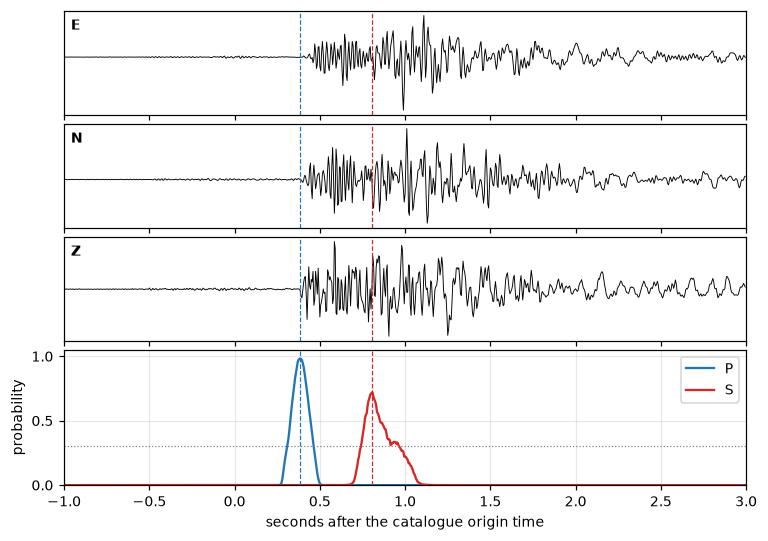

M 1.34 at 00:18:37


In [12]:
FS_RUN = {"CEC": 200.0, "BG": 250.0}                        # every other network: its recorded 100 Hz
e = ev.iloc[(ev.t - (obspy.UTCDateTime("2022-10-20T00:18:38") - T0)).abs().argmin()]
s56 = nodes.set_index("sta").loc["S56"]
print(f"rates given to PhaseNet: {FS_RUN}, every other station 100 Hz; "
      f"S56 is {np.hypot((s56.lat - e.lat) * gd.KM_LAT, (s56.lon - e.lon) * gd.KM_LON):.1f} km from the epicentre")
x = prepare(read_station("CEC", "S56"), 200.0)
prob = predict(x)
i0, n = int((e.t - 1) * 200), 800                            # from 1 s before the origin time, 4 s long
tt = np.arange(n) / 200 - 1
fig, axs = plt.subplots(4, 1, figsize=(8, 5.6), sharex=True, gridspec_kw=dict(hspace=0.08, height_ratios=[1, 1, 1, 1.3]))
for ax, k, lab in zip(axs, range(3), "ENZ"):
    ax.plot(tt, x[k, i0:i0 + n], c="k", lw=0.6); ax.set_yticks([]); ax.grid(False)
    ax.text(0.01, 0.82, lab, transform=ax.transAxes, fontweight="bold")
axs[3].plot(tt, prob[1, i0:i0 + n], c="tab:blue", label="P"); axs[3].plot(tt, prob[2, i0:i0 + n], c="tab:red", label="S")
axs[3].axhline(0.3, c="0.5", ls=":", lw=0.8)
for ph, i, p in detect(prob, 200.0):
    if i0 <= i < i0 + n:
        for ax in axs:
            ax.axvline((i - i0) / 200 - 1, c="tab:blue" if ph == "P" else "tab:red", lw=0.8, ls="--")
        print(f"{ph} pick {(i - i0) / 200 - 1:.2f} s after the origin time, probability {p:.2f}")
axs[3].set(ylim=(0, 1.05), ylabel="probability", xlabel="seconds after the catalogue origin time", xlim=(-1, 3))
axs[3].legend(loc="upper right")
plt.show()
print(f"M {e.mag:.2f} at {str(e.time)[11:19]}")


The P probability rises to almost 1 at the first motion, and the S probability peaks where the
horizontal components grow. The S peak is lower and wider than the P peak. Read it as the network
rating S as harder to place than P — an analyst would agree — but not as a calibrated chance: Part A
showed that a probability from a network need not mean what it says.


## B.3 · One hour on 131 stations

Now every station, at the rates chosen in B.2. Reading the hour takes a minute or
two the first time (most of it is the dense array); after that it comes from the disk.
Picking the hour on all stations takes seconds on a GPU and a few minutes on a CPU.


In [13]:
def pick_station(row, fs=None):
    """Read one station's hour, run PhaseNet at fs (default: the rate chosen in B.2), return its picks."""
    st = read_station(row.net, row.sta)
    fs = fs or FS_RUN.get(row.net, 100.0)
    if len(st) == 0:
        return pd.DataFrame(columns=["net", "sta", "row", "phase", "t", "prob", "fs"])
    out = [dict(net=row.net, sta=row.sta, row=row.row, phase=ph, t=i / fs, prob=p, fs=fs)
           for ph, i, p in detect(predict(prepare(st, fs)), fs)]
    return pd.DataFrame(out, columns=["net", "sta", "row", "phase", "t", "prob", "fs"])

t_start = time.time()
with ThreadPoolExecutor(16) as pool:                         # fetch in parallel, then pick in turn
    list(pool.map(lambda r: read_station(r.net, r.sta), stations.itertuples()))
empty = [f"{r.net}.{r.sta}" for r in stations.itertuples() if not (CACHE / f"{r.net}.{r.sta}.mseed").exists()]
mb = sum(p.stat().st_size for p in CACHE.glob("*.mseed")) / 1e6
print(f"read {len(stations)} stations ({mb:,.0f} MB) in {time.time() - t_start:.0f} s; no data in the hour: {empty}; "
      f"{len(stations) - len(empty)} stations with data")
t_start = time.time()
pk = pd.concat([pick_station(r) for r in stations.itertuples()], ignore_index=True)
print(f"picked in {time.time() - t_start:.0f} s: {len(pk):,} picks, {pk.phase.value_counts().to_dict()}")


read 131 stations (598 MB) in 36 s; no data in the hour: ['BG.FFA', 'NC.NLB']; 129 stations with data


picked in 82 s: 27,714 picks, {'P': 13993, 'S': 13721}


Each dot below is one pick with a probability of at least 0.5, placed at its time and at its
station's row; rows follow A–A′, and the shaded rows are dense-array nodes. An earthquake appears as
a column: it reaches every station within a few seconds, so its picks stand almost on one vertical
line. The three boxes are drawn again underneath, stretched out in time.


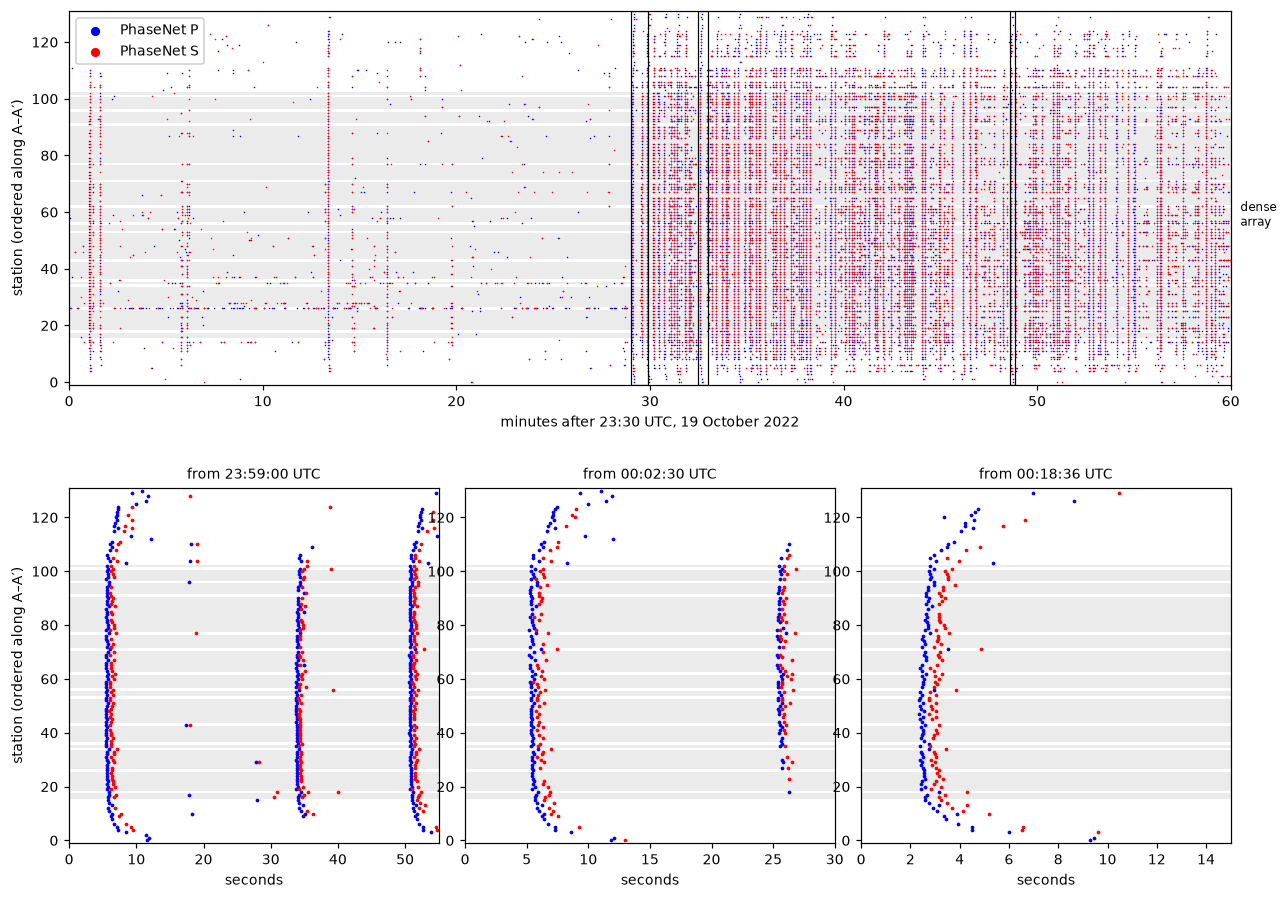

In [14]:
from matplotlib.patches import Rectangle
strong = pk[pk.prob >= 0.5]
ZOOM = [(1740, 1795), (1950, 1980), (2916, 2931)]           # seconds after 23:30: the burst, the M 3.2, the M 1.3
cec_rows = stations.row[stations.net == "CEC"]
fig = plt.figure(figsize=(12, 8.5))
top = fig.add_axes([0.07, 0.56, 0.88, 0.40])
bot = [fig.add_axes([0.07 + k * 0.30, 0.07, 0.28, 0.38]) for k in range(3)]
for ax, (a, b), size, zoom in [(top, (0, 3600), 1.0, False)] + [(z, w, 6, True) for z, w in zip(bot, ZOOM)]:
    q = strong[(strong.t >= a) & (strong.t < b)]
    for ph, c in (("P", "blue"), ("S", "red")):
        r = q[q.phase == ph]
        ax.scatter((r.t - a) if zoom else r.t / 60, r.row, s=size, c=c, lw=0, label=f"PhaseNet {ph}")
    for r in cec_rows:
        ax.axhspan(r - .5, r + .5, color="0.92", lw=0, zorder=0)
    ax.set_ylim(-1, len(stations)); ax.grid(False)
    if zoom:
        ax.set_xlim(0, b - a); ax.set_xlabel("seconds")
        ax.set_title(f"from {str(T0 + a)[11:19]} UTC", fontsize=9)
for a, b in ZOOM:
    top.add_patch(Rectangle((a / 60, -1), (b - a) / 60, len(stations) + 1, fill=False, ec="k", lw=0.8))
top.set(xlim=(0, 60), xlabel="minutes after 23:30 UTC, 19 October 2022", ylabel="station (ordered along A–A′)")
top.text(60.5, cec_rows.mean(), "dense\narray", va="center", fontsize=8)
top.legend(loc="upper left", markerscale=6, framealpha=.95)
bot[0].set_ylabel("station (ordered along A–A′)")
plt.show()


Three things stand out.

- **The burst.** For the first half hour there are a few columns; from 23:59 on there is hardly a gap. The
  catalogue lists 67 earthquakes in this hour, and the top panel suggests that PhaseNet sees many
  more. B.5 counts them.
- **The moveout.** In each zoom the P picks (blue) form a curve: the stations nearest the source
  pick first, and the farther ones, at both ends of A–A′, later. The S picks (red) follow the same
  shape, later and spread wider, because S travels at a little more than half the speed of P.
- **Picks that belong to no column.** Isolated dots, some on a few rows that pick much more often
  than their neighbours. They are either very small earthquakes seen by one or two sensitive stations,
  or noise. B.6 and B.7 look at them.


## B.4 · Does PhaseNet agree with the analysts?

The catalogue's picks are on the permanent stations only (the dense array was never part of the
routine network). For each of them we look for a PhaseNet pick of the same phase on the same
station within 0.5 s. The share that finds one is the **recall**: the fraction of the analysts'
picks that PhaseNet also made. The time difference, PhaseNet minus catalogue, is the **residual**.
We report its median, which says whether PhaseNet picks systematically early or late, and its
median absolute deviation (MAD), which says how far a typical pick strays; both ignore the few
matches far out in the tails, which the 0.5 s window lets in.


In [15]:
def match(pk, ref, tol=0.5):
    """For every reference pick, the signed time to the nearest PhaseNet pick of its phase on its station."""
    out = []
    for (sta, ph), g in ref.groupby(["sta", "phase"]):
        t = np.sort(pk.t[(pk.sta == sta) & (pk.phase == ph)].values)
        if len(t) == 0:
            d = np.full(len(g), np.inf)
        else:
            j = np.searchsorted(t, g.t.values)
            lo, hi = t[np.clip(j - 1, 0, len(t) - 1)] - g.t.values, t[np.clip(j, 0, len(t) - 1)] - g.t.values
            d = np.where(np.abs(lo) < np.abs(hi), lo, hi)
        out.append(g.assign(res=d, found=np.abs(d) <= tol))
    return pd.concat(out)

ref = ncedc[ncedc.sta.isin(stations.sta[stations.net != "CEC"])]
m = match(pk, ref)
def summary(m):
    rows = []
    for (ph, mode), g in m.groupby(["phase", "mode"]):
        r = g.res[g.found]
        rows.append(dict(phase=ph, picks=mode, n=len(g), recall=g.found.mean(),
                         median_ms=1000 * r.median(), mad_ms=1000 * (r - r.median()).abs().median(),
                         mean_ms=1000 * r.mean(), std_ms=1000 * r.std()))
    return pd.DataFrame(rows).round(2)
print(summary(m).to_string(index=False))
print(f"\nPhaseNet made {(pk.net != 'CEC').sum():,} picks on these stations; the catalogue {len(ref):,}")


phase     picks   n  recall  median_ms  mad_ms  mean_ms  std_ms
    P automatic 627    0.83       -4.0     6.0    -4.91   48.24
    P    manual 657    0.90        0.0    10.0     3.50   61.11
    S    manual  60    0.97       17.0    26.0    30.52   86.19

PhaseNet made 9,921 picks on these stations; the catalogue 1,344


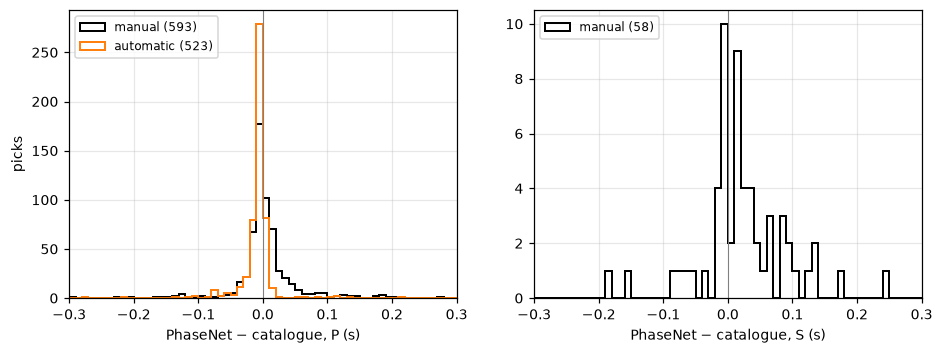

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
bins = np.arange(-0.3, 0.3001, 0.01)
for ax, ph in zip(axs, "PS"):
    for mode, c in (("manual", "k"), ("automatic", "tab:orange")):
        r = m.res[(m.phase == ph) & (m["mode"] == mode) & m.found]
        if len(r):
            ax.hist(r, bins, histtype="step", color=c, lw=1.3, label=f"{mode} ({len(r)})")
    ax.axvline(0, c="0.5", lw=0.7)
    ax.set(xlabel=f"PhaseNet − catalogue, {ph} (s)", xlim=(-0.3, 0.3))
    ax.legend(loc="upper left", fontsize=8)
axs[0].set_ylabel("picks")
plt.show()


PhaseNet finds most of the analysts' picks, and where it does, a typical P pick lies within about a
hundredth of a second of theirs (the MAD). Three details are worth a look.

- PhaseNet agrees more closely with the network's *automatic* P picks than with the manual ones, and
  sits a few milliseconds earlier than the automatic picker.
- Against the manual P picks the histogram has a tail to the right: on some stations PhaseNet picks
  later than the analyst — perhaps where the first motion is weak and the analyst caught it while
  the network did not.
- S is harder: the residuals are wider and PhaseNet picks S slightly later than the analysts did.
  There are only 61 manual S picks in the hour, so the S statistics are thin.

How does this compare with the paper? On its test set of NCEDC records, Zhu & Beroza (2019, Table 1)
report, for residuals below 0.5 s, a mean of 2 ms and a standard deviation of 52 ms for P, and 3 ms
and 83 ms for S. The `mean_ms` and `std_ms` columns above are the same two statistics for this hour,
and they are close to the paper's: PhaseNet does about as well on the Geysers hour as on its own
test set. The standard deviation is much larger than the MAD because it is pulled out by the few
residuals far in the tails.

The last line of the printout is the larger story. PhaseNet made many times more picks on these
stations than the catalogue holds. Some of those belong to earthquakes the catalogue does contain
but at stations the analysts did not use; many belong to earthquakes the catalogue does not contain;
some are false. The analysts' picks cannot tell those apart — they only test recall. B.5 uses the
dense array to sort them.


## B.5 · How many earthquakes does the catalogue miss?

A pick on one station could be anything. Picks on many stations at once mean an earthquake, because
noise at stations hundreds of metres apart does not line up in time. The dense array lets us use
this directly. An earthquake under the array reaches its nodes within about a second (the zooms of
B.3), so we call it a **detection** when at least 15 nodes make a P pick (probability ≥ 0.5) within one second
of each other. A run of such moments with no pause of 2 s or more counts as one detection.

This is the simplest form of **association**, the step that groups picks into earthquakes;
Session 2, *Location & relocation*, located earthquakes from picks that were already grouped. It
says nothing yet about where each earthquake is; it only counts them.


In [17]:
def array_detections(pk, n_min=15, width=1.0, pause=2.0, p_min=0.5):
    """Times when at least n_min dense-array nodes pick P within `width` seconds of each other."""
    p = pk[(pk.net == "CEC") & (pk.phase == "P") & (pk.prob >= p_min)].sort_values("t")
    t, sta = p.t.values, p.sta.values
    end = np.searchsorted(t, t + width)
    n = np.array([len(set(sta[i:j])) for i, j in zip(range(len(t)), end)])
    hit = t[n >= n_min]
    return hit[np.r_[True, np.diff(hit) > pause]] if len(hit) else hit

N_MIN, WIDTH, PAUSE, P_MIN = 15, 1.0, 2.0, 0.5
det = array_detections(pk, N_MIN, WIDTH, PAUSE, P_MIN)
print(f"a detection: at least {N_MIN} nodes with P probability ≥ {P_MIN} within {WIDTH:.0f} s; "
      f"a pause of {PAUSE:.0f} s ends it")
LAG, TOL = 0.7, 1.5         # a catalogue earthquake under the array reaches it about LAG s after its origin
d = np.array([np.abs(det - (te + LAG)).min() for te in ev.t])
found = d <= TOL
in_cat = np.array([np.abs(ev.t.values + LAG - td).min() <= TOL for td in det])
print(f"matched when the detection is within {TOL} s of origin time + {LAG} s")
print(f"{len(det)} detections in the hour; {in_cat.sum()} match a catalogue earthquake, {(~in_cat).sum()} do not")
print(f"of the {len(ev)} catalogue earthquakes, {found.sum()} were detected; "
      f"{ev.mag.isna().sum()} of the {len(ev)} have no magnitude in the catalogue")
gap = np.array([td - ev.t[ev.t < td].max() if (ev.t < td).any() else np.inf for td in det[~in_cat]])
print(f"unmatched detections: {np.mean(gap < 60):.0%} come within a minute after a catalogue earthquake, "
      f"{np.mean(det[~in_cat] > ev.t[ev.mag >= 3].min()):.0%} after the first M ≥ 3")
print("catalogue earthquakes not detected (magnitude, distance from the array centre):")
c = nodes[["lat", "lon"]].mean()
miss = ev[~found].assign(km=lambda q: np.hypot((q.lat - c.lat) * gd.KM_LAT, (q.lon - c.lon) * gd.KM_LON))
print(miss[["time", "mag", "km"]].round(2).to_string(index=False))


a detection: at least 15 nodes with P probability ≥ 0.5 within 1 s; a pause of 2 s ends it
matched when the detection is within 1.5 s of origin time + 0.7 s
135 detections in the hour; 60 match a catalogue earthquake, 75 do not
of the 67 catalogue earthquakes, 61 were detected; 8 of the 67 have no magnitude in the catalogue
unmatched detections: 77% come within a minute after a catalogue earthquake, 96% after the first M ≥ 3
catalogue earthquakes not detected (magnitude, distance from the array centre):
                       time  mag   km
2022-10-19T23:59:46.850000Z 1.43 2.14
2022-10-20T00:00:56.190000Z  NaN 0.44
2022-10-20T00:04:14.210000Z  NaN 1.07
2022-10-20T00:04:26.660000Z  NaN 1.29
2022-10-20T00:16:04.240000Z 0.85 0.89
2022-10-20T00:18:52.390000Z 0.75 1.00


The figure counts both as the hour goes on: the catalogue's earthquakes and the array's detections.


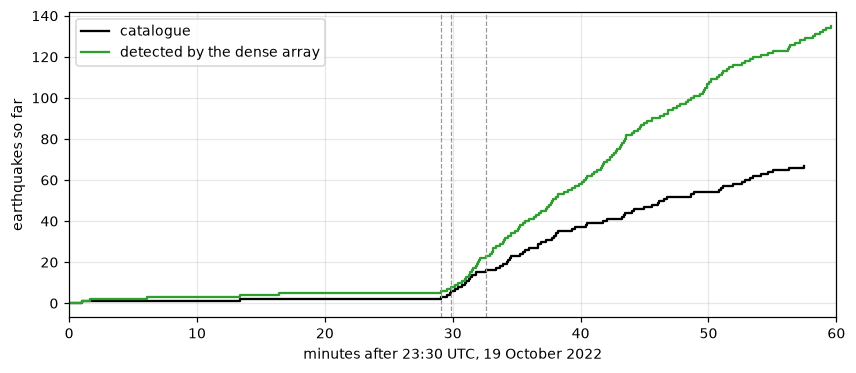

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(np.r_[0, np.sort(ev.t)] / 60, np.arange(len(ev) + 1), where="post", c="k", lw=1.5, label="catalogue")
ax.step(np.r_[0, det] / 60, np.arange(len(det) + 1), where="post", c="tab:green", lw=1.5, label="detected by the dense array")
for te, m in zip(ev.t, ev.mag):
    if m >= 3:
        ax.axvline(te / 60, c="0.6", ls="--", lw=0.8)
ax.set(xlim=(0, 60), xlabel="minutes after 23:30 UTC, 19 October 2022", ylabel="earthquakes so far")
ax.legend(loc="upper left")
plt.show()


Before the burst, the array and the catalogue both count only a few earthquakes. From the first M 3.3
(dashed lines mark the three M ≥ 3) the array's count pulls away. Most of the unmatched detections
come during the burst, within a minute of a catalogued earthquake (printed above) — the time when
earthquakes follow each other within seconds and their records overlap.

Are the extra detections real earthquakes? Below are four of them, picked at random: the vertical
records of every third dense-array node, in A–A′ order, with PhaseNet's picks. Each trace is scaled
by its own noise level before the event, so that what rises above the noise is visible.


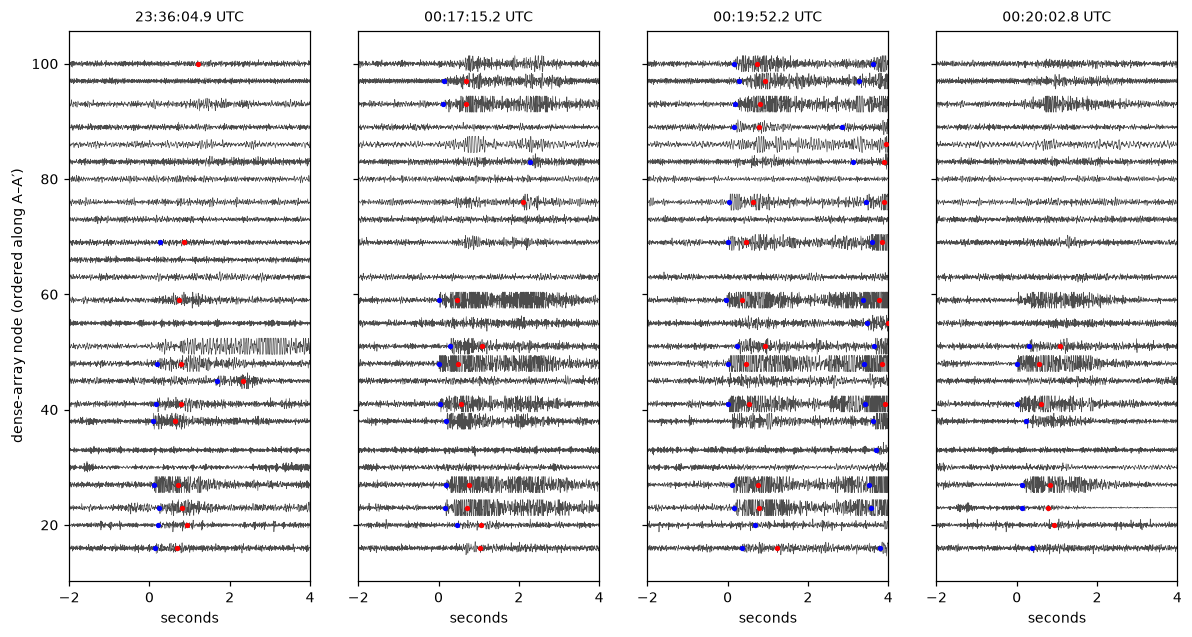

In [19]:
new = det[~in_cat]
show = np.sort(np.random.default_rng(5).choice(new, 4, replace=False))
cec = stations[stations.net == "CEC"]
fig, axs = plt.subplots(1, 4, figsize=(13, 6.5), sharey=True)
for ax, td in zip(axs, show):
    for r in cec.iloc[::3].itertuples():                       # every third node
        z = read_station("CEC", r.sta).select(component="Z")
        if not len(z):
            continue
        w = z.slice(T0 + td - 2, T0 + td + 4)
        if not len(w):                                          # a node with a gap here
            continue
        tr = w.merge(fill_value=0)[0].copy()
        tr.detrend("demean"); tr.filter("bandpass", freqmin=10, freqmax=80)
        noise = tr.data[:300].std() + 1e-12                    # the 1.5 s before the detection
        y = np.clip(tr.data / (6 * noise), -1, 1)               # noise stays small; arrivals stand out
        ax.plot(np.arange(tr.stats.npts) / 200 - 2, r.row + 1.4 * y, c="0.3", lw=0.4)
    q = pk[(pk.net == "CEC") & pk.sta.isin(cec.sta.iloc[::3]) & (pk.t > td - 2) & (pk.t < td + 4)]
    for ph, col in (("P", "blue"), ("S", "red")):
        w = q[q.phase == ph]
        ax.scatter(w.t - td, w.row, s=6, c=col, zorder=3)
    ax.set_title(f"{str(T0 + td)[11:21]} UTC", fontsize=9); ax.set_xlabel("seconds"); ax.set_xlim(-2, 4); ax.grid(False)
axs[0].set_ylabel("dense-array node (ordered along A–A′)")
plt.show()


In each panel, P picks (blue) line up across many nodes and S picks (red) follow a few tenths of a
second later on the same nodes — the signature of a small earthquake close beneath the array. In the
first panel the arrivals are weak and only part of the array picks them; in the other three they
are clear on most nodes. These four, at least, are earthquakes the catalogue does not contain.

Two cautions before counting all the unmatched detections as missed earthquakes. The matching uses
the origin times only, so a catalogued earthquake whose P reaches the array unusually late, or whose
S triggers a second detection after a pause, can be counted twice. And the catalogue is the routine
network's — tens of stations, BG boreholes among them — which has to decide what is an earthquake
with far fewer stations close to each source than the array has.


## B.6 · Which sampling rate?

PhaseNet was trained on records sampled at 100 Hz, but it has no notion of seconds: it sees a
sequence of numbers. Give it a record sampled at 500 Hz and every wave is spread over five times as
many samples as at 100 Hz — a 25 Hz wave, 4 samples per cycle at 100 Hz, takes 20 samples, which to
the network looks like a 5 Hz wave did in training. The usual practice is therefore to resample
everything to 100 Hz. That has a cost: to resample to 100 Hz without aliasing, everything above
about 40 Hz has to be filtered out first.

Does that cost matter here? The Geysers earthquakes are small, and small earthquakes radiate their
energy at high frequencies. Below is the spectrum of the P wave of the M 1.3 from B.2 at the BG
borehole station SQK, recorded at 500 Hz, next to the noise just before it.


at SQK, S arrives 0.39 s after P; the P window is 0.37 s long


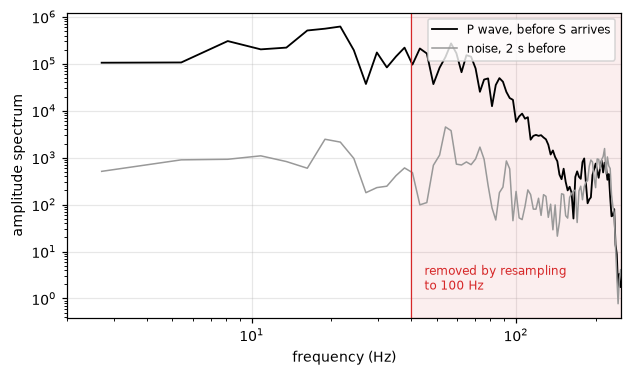

SQK, M 1.34: 17% of the P-wave energy above 2 Hz lies above 40 Hz, where the signal is 11 times the noise


In [20]:
tr = read_station("BG", "SQK").select(channel="DPZ").merge(fill_value=0)[0].copy()
tr.detrend("demean")
near = pk[(pk.sta == "SQK") & ((pk.t - e.t).abs() < 3)]
tp = T0 + near.t[near.phase == "P"].min()
ts = T0 + near.t[(near.phase == "S") & (near.t > tp - T0)].min()
win = ts - tp - 0.02                                                # the P wave only: stop before S
print(f"at SQK, S arrives {ts - tp:.2f} s after P; the P window is {win:.2f} s long")
def spectrum(t0, sec=win):
    x = tr.slice(t0, t0 + sec).data.astype(float); x = (x - x.mean()) * np.hanning(len(x))
    return np.fft.rfftfreq(len(x), 1 / tr.stats.sampling_rate), np.abs(np.fft.rfft(x))
f, s_sig = spectrum(tp - 0.02); _, s_noise = spectrum(tp - 2.0)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(f[1:], s_sig[1:], c="k", lw=1.2, label="P wave, before S arrives")
ax.loglog(f[1:], s_noise[1:], c="0.6", lw=1.0, label="noise, 2 s before")
ax.axvspan(40, 250, color="tab:red", alpha=0.08); ax.axvline(40, c="tab:red", lw=0.8)
ax.text(45, s_noise[1:].min() * 2, "removed by resampling\nto 100 Hz", color="tab:red", fontsize=8)
ax.set(xlim=(2, 250), xlabel="frequency (Hz)", ylabel="amplitude spectrum")
ax.legend(loc="upper right", fontsize=8)
plt.show()
band = f > 2
print(f"SQK, M {e.mag:.2f}: {(s_sig[f > 40] ** 2).sum() / (s_sig[band] ** 2).sum():.0%} of the P-wave energy "
      f"above 2 Hz lies above 40 Hz, where the signal is {np.median(s_sig[f > 40] / s_noise[f > 40]):.0f} times the noise")


A good part of this small earthquake's P-wave energy lies above 40 Hz, well above the noise (the
share is printed above). A picker given the 100 Hz version of this record never sees it. This is one
earthquake at one station, but small earthquakes in general radiate more of their energy at high
frequencies than large ones do. So should the BG boreholes keep the
500 Hz they were recorded at? We run them three ways: resampled to 100 Hz, resampled to 250 Hz, and
left at 500 Hz.

We need **two measures**, because a picker can fail in two ways: it can miss arrivals, and it can
invent them.

1. **Recall** of the analysts' picks (B.4): how many of the arrivals we know about does it find?
2. **Share of picks that follow an array detection.** A real arrival at a station comes from an
   earthquake; most earthquakes in this hour were detected by the dense array (B.5), and their waves
   reach a station within a few seconds of that detection (at most the station's distance divided by
   4 km/s, plus 3 s for S). A pick that follows no detection is either from an earthquake the array
   did not see or is false. Random times give the share expected by chance.


In [21]:
c = nodes[["lat", "lon"]].mean()
dist = dict(zip(stations.sta, np.hypot((stations.lat - c.lat) * gd.KM_LAT, (stations.lon - c.lon) * gd.KM_LON)))

def follows(t, km):
    """True where time t (s) lies between 1 s before a detection and km/4 + 3 s after it."""
    j = np.searchsorted(det, t) - 1
    lag = np.where(j >= 0, t - det[np.clip(j, 0, None)], np.inf)
    return (lag >= -1) & (lag <= np.asarray(km) / 4.0 + 3)

rows = []
for group, net, rates in (("BG, recorded at 500 Hz", "BG", (100.0, 250.0, 500.0)),):
    sts = stations[stations.net == net]
    for fs in rates:
        p = pd.concat([pick_station(r, fs) for r in sts.itertuples()])
        s = summary(match(p, ref[ref.net == net])).set_index(["phase", "picks"]).recall
        km = p.sta.map(dist).values
        fol = follows(p.t.values, km)
        rows.append(dict(stations=group, rate=int(fs), recall_P=s.get(("P", "manual")), recall_S=s.get(("S", "manual")),
                         picks=len(p), n_follow=int(fol.sum()), n_none=int((~fol).sum()), follow=fol.mean(),
                         chance=follows(np.random.default_rng(0).uniform(0, 3600, len(p)), km).mean()))
rate = pd.DataFrame(rows)
print(rate.drop(columns="stations").round(2).to_string(index=False))


 rate  recall_P  recall_S  picks  n_follow  n_none  follow  chance
  100      0.77      0.96   4936      4399     537    0.89    0.16
  250      0.93      1.00   9027      6418    2609    0.71    0.15
  500      0.90      1.00   9630      5741    3889    0.60    0.15


The figure puts the two measures side by side: recall of the analysts' P picks on the left, the
share of picks that follow an array detection on the right (the dotted line is what random times
would give).


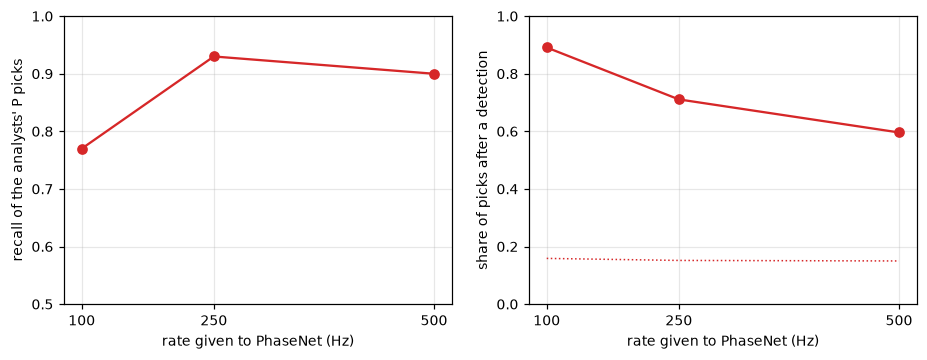

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].plot(rate.rate, rate.recall_P, "o-", c="tab:red")
axs[1].plot(rate.rate, rate.follow, "o-", c="tab:red"); axs[1].plot(rate.rate, rate.chance, ":", c="tab:red", lw=1)
axs[0].set(xlabel="rate given to PhaseNet (Hz)", ylabel="recall of the analysts' P picks", ylim=(0.5, 1))
axs[1].set(xlabel="rate given to PhaseNet (Hz)", ylabel="share of picks after a detection", ylim=(0, 1))
for ax in axs: ax.set_xticks([100, 250, 500])
plt.show()


The rate changes two things the network sees: how many samples a wave is spread over, and how many
seconds the 3,000-sample standardisation window spans. (The pick rule is set in seconds, so it is
the same at every rate.) The table and the figure show what that does.

**From 100 to 250 Hz, recall rises sharply.** At 100 Hz the boreholes miss many more of the
analysts' picks: the energy above 40 Hz was part of what made those arrivals pickable. The picks
that follow a detection (`n_follow`) increase — more arrivals of real earthquakes are found — and so
do the picks that follow none (`n_none`), so the *share* that follows a detection falls.

**From 250 to 500 Hz, recall does not improve.** Compare `n_follow` and `n_none` between the two rows:
going to 500 Hz buys no more of the picks that follow a detection, while the picks that follow none
keep growing. At 500 Hz every wave is spread over twice as many samples again, and short bursts of
noise begin to look to the network like the arrivals it learned.

This is the trade-off between **recall** and **precision** that Part A met with the probability
threshold, now set by a different knob. The rate is a **hyperparameter**, and choosing it took two
measures: on recall alone, 250 and 500 Hz look alike; on the share of picks after a detection alone,
100 Hz looks best. Together they point to 250 Hz for the boreholes, which is what B.3 used — a
judgement, since how many false picks are worth how many found arrivals depends on what the picks
are for. The dense array keeps its recorded 200 Hz and the other stations their 100 Hz. The general
lesson: a test against labels measures what the labels contain — here, recall — and says nothing
about the picks they do not contain.

*Try it:* raise the NC stations, recorded at 100 Hz, to 200 Hz with `pick_station(row, 200.0)`.
Raising the rate adds no high frequencies — there are none to add — but spreads every wave over
twice as many samples. Measure both quantities, and decide whether you would keep it.


## B.7 · Where does the picker go wrong?

Every station is run the same way, but stations are not alike. We count, for each station, its
picks and the share of them that follow an array detection (B.6), and list the stations at both
ends.


In [23]:
per = pk.assign(follow=follows(pk.t.values, pk.sta.map(dist).values)).groupby(["net", "sta", "row"]).agg(
    picks=("t", "size"), P=("phase", lambda q: (q == "P").sum()), S=("phase", lambda q: (q == "S").sum()),
    follow=("follow", "mean")).reset_index()
per = stations[["net", "sta", "row", "kind"]].merge(per, on=["net", "sta", "row"], how="left").fillna({"picks": 0, "P": 0, "S": 0})
per["km"] = per.sta.map(dist).round(1)
print("stations with fewer than 20 picks in the hour (km: distance from the dense array):")
print(per[per.picks < 20][["net", "sta", "kind", "km", "picks"]].to_string(index=False))
print("\nthe five stations with the most picks that follow no detection:")
per["lonely"] = per.picks * (1 - per.follow)
print(per.nlargest(5, "lonely")[["net", "sta", "kind", "picks", "follow"]].round(2).to_string(index=False))


stations with fewer than 20 picks in the hour (km: distance from the dense array):
net   sta          kind   km  picks
 NC   GSS  short-period 22.4    0.0
CEC   S45      CEC node  0.4   18.0
 NC   GSG  short-period  9.8    0.0
 NC  GWKB     broadband 37.4   11.0
 NP  1744 strong-motion 23.6   10.0
 BG   FFA            BG  8.6    0.0
 NC   GSX     broadband 24.8   12.0
 NC   NLB  short-period 23.7    0.0
 CE 68208 strong-motion 36.4   19.0
 NC  NMTB     broadband 31.2   11.0

the five stations with the most picks that follow no detection:
net sta     kind  picks  follow
 BG BUC       BG  623.0    0.26
CEC S38 CEC node  398.0    0.59
 BG SB4       BG  413.0    0.62
 BG MCL       BG  366.0    0.62
CEC S09 CEC node  362.0    0.65


The figure shows every station's picks in the hour, in A–A′ order: the part that follows an array
detection and the part that does not.


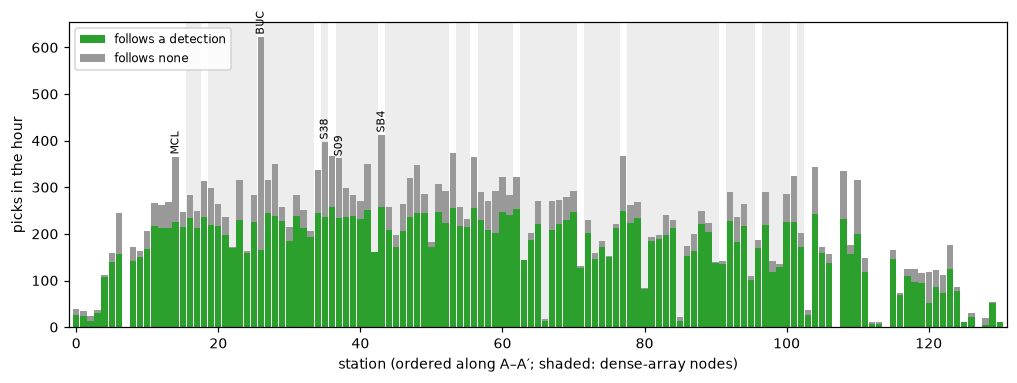

In [24]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(per.row, per.picks * per.follow, color="tab:green", width=0.9, label="follows a detection")
ax.bar(per.row, per.picks * (1 - per.follow), bottom=per.picks * per.follow, color="0.6", width=0.9, label="follows none")
for r in stations.row[stations.net == "CEC"]:
    ax.axvspan(r - .5, r + .5, color="0.93", lw=0, zorder=0)
for r in per.nlargest(5, "lonely").itertuples():
    ax.text(r.row, r.picks + 10, r.sta, ha="center", fontsize=7, rotation=90)
ax.set(xlim=(-1, len(stations)), xlabel="station (ordered along A–A′; shaded: dense-array nodes)", ylabel="picks in the hour")
ax.legend(loc="upper left", fontsize=8); ax.grid(False)
plt.show()


Three kinds of failure show up.

- **Stations without signal.** A few stations give no picks at all. For two of them the archive holds
  files for the day but no data for this hour (B.3). Others are tens of kilometres from the array
  (the `km` column), where the small earthquakes of the hour are too weak to record. One, NC.GSG,
  records nothing above its noise even for the M 3.2 at about 10 km: a dead channel. A picker cannot
  tell a dead station from a quiet one; a count of picks per station, read with its distance, can.
- **Stations that pick too often.** A handful of stations — some BG boreholes, some dense-array
  nodes — make many picks that follow no detection. Some may be real earthquakes too small or too far
  for the array to detect; on a station that picks several times a minute through the quiet first
  half hour (the BUC row in the B.3 figure), most must be noise. A practical pipeline checks each
  station's pick rate and the share of its picks that associate with earthquakes, and looks at the
  records of the outliers.
- **S on one component.** Most NC short-period stations record only the vertical component. S
  arrives mostly on the horizontals, so on these stations PhaseNet sees one third of its usual input
  (the missing components are zeros, and the standardisation scales the live one up to make up for
  them). Compare their S picks with the three-component stations:


In [25]:
ncomp = {}
for r in stations[stations.net != "CEC"].itertuples():
    st = read_station(r.net, r.sta)
    ncomp[r.sta] = len({tr.stats.channel[-1] for tr in st})
per["components"] = per.sta.map(ncomp).fillna(3).astype(int)
nc = per[(per.net == "NC") & (per.picks > 0)]
print(nc.groupby("components")[["P", "S"]].sum().assign(S_per_P=lambda q: (q.S / q.P).round(2)))
ana = ref[(ref.net == "NC") & (ref.phase == "S")].sta.map(ncomp).value_counts()
print("the analysts' S picks on these stations, by number of components:", ana.to_dict())
# a check that needs no labels: an S pick should follow a P pick on the same station by a plausible S-P time
q = pk[pk.sta.isin(nc.sta)].sort_values("t")
def has_p_before(g):
    tp = np.sort(g.t[g.phase == "P"].values); ts = g.t[g.phase == "S"].values
    j = np.searchsorted(tp, ts) - 1
    lag = np.where(j >= 0, ts - tp[np.clip(j, 0, None)], np.inf)
    return pd.Series(dict(S=len(ts), with_P=int(((lag > 0.1) & (lag < 8)).sum())))
chk = q.groupby("sta").apply(has_p_before).join(per.set_index("sta").components).groupby("components").sum()
print((chk.with_P / chk.S).round(2).rename("share of S picks with a P pick 0.1-8 s before").to_string())


                P      S  S_per_P
components                       
1           318.0  273.0     0.86
3           131.0  112.0     0.85
the analysts' S picks on these stations, by number of components: {3: 10, 1: 5}
components
1    0.86
3    0.87


PhaseNet makes about as many S picks per P pick on the vertical-only stations as on the
three-component ones. Whether those S picks are right, the analysts can hardly tell us: they made
only five S picks on these stations in the hour. One check needs no labels: an S pick should come a
plausible time after a P pick on the same station (here between 0.1 and 8 s; Part A used the same
physics). The last lines give that share for the two kinds of station, and it is the same. By this
check the S picks on vertical-only stations look as plausible as the others — but the check cannot
tell a correctly timed S from one that is a few tenths of a second off. Part A showed that the
catalogue's S labels almost vanish on vertical-only stations, and PhaseNet was trained on that
catalogue, so it has probably seen few examples of S on a vertical component alone. An S pick from such a station deserves less trust than
its probability suggests.

## What we found

The questions at the top, answered.

1. **The data.** One hour on 129 stations with data: 55 permanent stations within 40 km (BG
   boreholes at 500 Hz, other networks at 100 Hz), read by byte range from the NCEDC archive, and 74
   dense-array nodes at 200 Hz from Google Cloud Storage.
2. **The picker.** PhaseNet is a U-Net that turns three components into P and S probabilities;
   on a continuous record it needs a running standardisation and is applied to the whole record at
   once.
3. **One hour.** Earthquakes appear as columns of picks across the stations, with P and S moveout
   along A–A′, and a quiet half-hour turns into a burst.
4. **Agreement with the analysts.** PhaseNet finds most of the analysts' picks (a share of 0.83 to 0.97) and
   agrees with them to about 10 ms for P; S is wider.
5. **The catalogue.** The dense array detects about twice as many earthquakes as the catalogue holds
   in this hour; the four we looked at are clear earthquakes, and most of the extra detections come
   during the burst.
6. **The sampling rate.** Lowering the boreholes' rate to 100 Hz loses real high-frequency arrivals;
   keeping their full 500 Hz adds picks that follow no detection without finding more. We chose
   250 Hz with two measures, recall and the share of picks that follow a detection.
7. **Failures.** Stations without signal, a few noisy stations, and S picks on vertical-only
   stations that the analysts' picks cannot check.

## Takeaways

**Machine learning**

- A network trained on one sampling rate sees samples, not seconds, so the rate we give it at
  inference is a hyperparameter that changes what it sees.
- A test against labels measures recall only; false picks need a second test that does not rely on
  the labels, such as agreement across many stations.
- A fully convolutional network can be applied to a record of any length in one pass, with a running
  standardisation standing in for the per-window standardisation it was trained with.

**Seismology**

- A deep-learning picker run on continuous data reproduces the analysts' P picks to about a
  hundredth of a second and makes far more S picks than a routine catalogue contains.
- In this hour, about half of the earthquakes the dense array detected are not in the routine
  catalogue, most of them during the burst, when records of successive earthquakes overlap.
- Small, close earthquakes can carry a sizeable share of their energy above 40 Hz, so data recorded
  at high rates should not be resampled to 100 Hz before picking without checking what is lost.

## References

- Zhu, W., & Beroza, G. C. (2019). PhaseNet: a deep-neural-network-based seismic arrival-time
  picking method. *Geophysical Journal International*, 216(1), 261.
  https://doi.org/10.1093/gji/ggy423
- NCEDC (2014). Northern California Earthquake Data Center. UC Berkeley Seismological Laboratory.
  Dataset. https://doi.org/10.7932/NCEDC